# 2. Análise dos parâmetros: autocorrelação e melhor lag

Mesmo procedimento do exemplo do professor (*Series Temporais Exp 04*), aplicado às nossas três bases: **dólar**, **Petrobras** e **volatilidade diária**.

1. normalizar a série com o mínimo e o máximo **do treino**;
2. olhar a **autocorrelação** (ACF) até 40 lags;
3. para cada dimensão (lag) de 1 a 30, ajustar o modelo linear `coefs = pinv(train) · trainTarget` e medir o **MSE na validação**;
4. escolher o lag com menor MSE de validação e medir o **MSE no teste**.

Divisão: 60% treino, 20% validação e 20% teste, em ordem cronológica, como no exemplo.

> **Uma correção em relação ao exemplo:** no original, a coluna de intercepto da validação é criada com `np.zeros_like` (zeros), enquanto a do treino e a do teste usam `np.ones_like` (uns). Isso tira o intercepto das previsões de validação e pode mudar o lag escolhido. Aqui as três bases usam **uns**.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import mean_squared_error as mse
from matplotlib import pyplot as plt

# Lê as planilhas do repositório (pasta dados/). No Colab, busca direto no GitHub.
URL = "https://raw.githubusercontent.com/BerzinMiguel/IA.2026.2/main/dados/"

def ler_serie(arquivo, coluna):
    for pasta in (Path("dados"), Path("../dados")):
        if (pasta / arquivo).exists():
            return pd.read_excel(pasta / arquivo)[coluna].dropna().to_numpy(dtype=float)
    return pd.read_excel(URL + arquivo)[coluna].dropna().to_numpy(dtype=float)

bases = {
    "Dólar": ler_serie("Dolar_tratado.xlsx", "Valor"),
    "Petrobras": ler_serie("Petrobras_tratado.xlsx", "Valor"),
    "Volatilidade": ler_serie("volatilidade.xlsx", "Volatilidade_Diaria"),
}
for nome, serie in bases.items():
    print(f"{nome}: {len(serie)} dias")

trainSplit = 0.6   # usado para treinar o modelo
validSplit = 0.2   # verificar se o modelo é adequado (escolha de parâmetros)
                   # os 20% finais ficam para o teste

Dólar: 1724 dias
Petrobras: 1711 dias
Volatilidade: 1710 dias


In [2]:
def acf_plot(data, lags, titulo="Autocorrelation Plot"):
    """Mesma função do exemplo do professor (com título)."""
    values = []
    for i in range(lags):
        values.append(data.autocorr(i))
    plt.plot(np.zeros_like(values))
    plt.plot(np.ones_like(values) * 1.96 * (1 / np.sqrt(len(data))))
    plt.plot(np.ones_like(values) * (-1.96) * (1 / np.sqrt(len(data))))
    plt.bar(range(lags), values, width=0.4)
    plt.title(titulo)
    plt.xlabel("Lags")
    plt.ylabel("Autocorrelation")
    plt.show()

In [3]:
def preparar(dataset):
    """Normaliza com mínimo e máximo do TREINO, como no exemplo do professor."""
    trainSize = int(np.floor(trainSplit * len(dataset)))
    validSize = int(np.floor(validSplit * len(dataset)))
    maxData = np.max(dataset[0:trainSize])
    minData = np.min(dataset[0:trainSize])
    ndataset = (dataset - minData) / (maxData - minData)
    return pd.Series(ndataset), trainSize, validSize


def janelas(datasetSeries, dim, stepahead, trainSize, validSize):
    """Monta as janelas de lags (coluna 0 = alvo; colunas seguintes = passado).

    Com stepahead = 1 é exatamente o datasetShifted do professor. Para
    stepahead = h, as entradas são os valores de h até h+dim-1 dias antes do alvo.
    """
    datasetShifted = pd.concat([datasetSeries.shift(i) for i in range(dim + stepahead)], axis=1)
    entradas = datasetShifted.iloc[:, stepahead:]
    alvo = datasetShifted.iloc[:, 0]
    inicio = dim + stepahead - 1   # primeira linha sem valores vazios (= dim quando stepahead = 1)
    blocos = {
        "train": slice(inicio, trainSize),
        "valid": slice(trainSize, trainSize + validSize),
        "test": slice(trainSize + validSize, None),
    }
    return {nome: (entradas.iloc[b].values, alvo.iloc[b].values) for nome, b in blocos.items()}

## Autocorrelação

As linhas horizontais marcam ±1,96/√n, o limite de significância de 95%. Barras fora dessa faixa indicam que o valor de *k* dias atrás tem relação com o de hoje.

Os preços (dólar e Petrobras) dependem muito do dia anterior. Por isso a ACF deles fica alta em todos os lags e, sozinha, não indica um lag. Para eles também mostramos a ACF da **variação diária** (diferença entre um dia e o anterior), que mostra melhor a dependência de curto prazo.

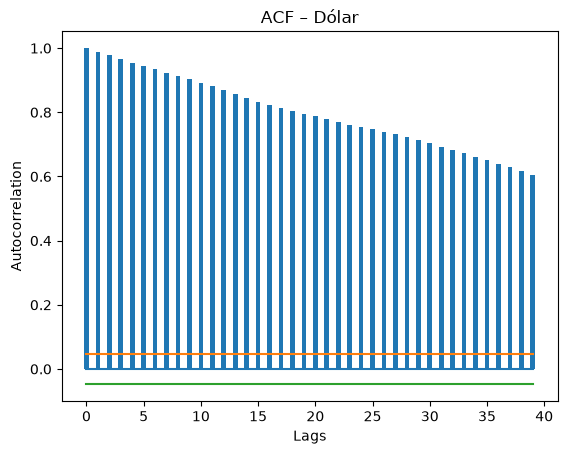

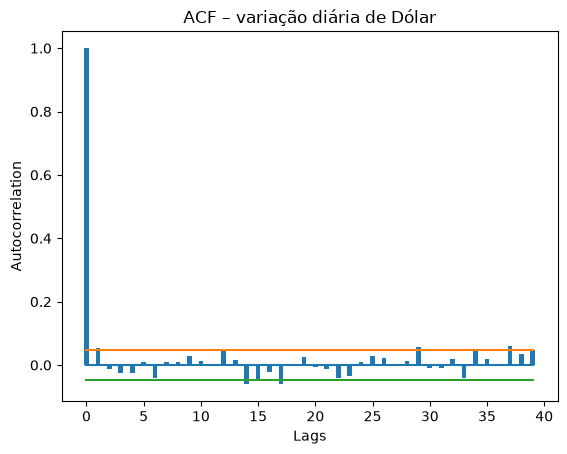

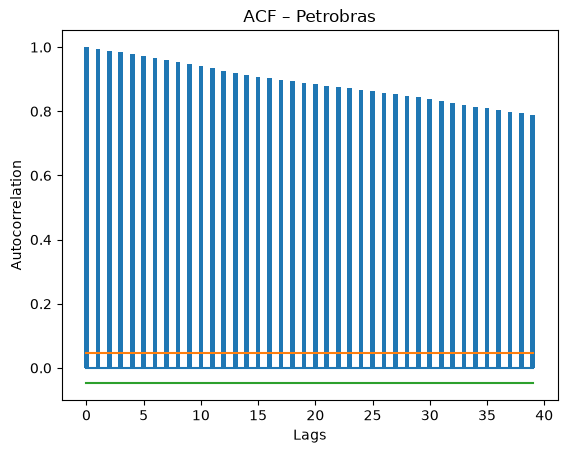

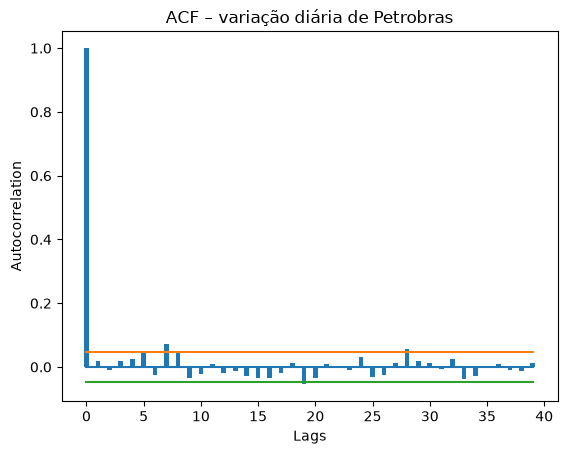

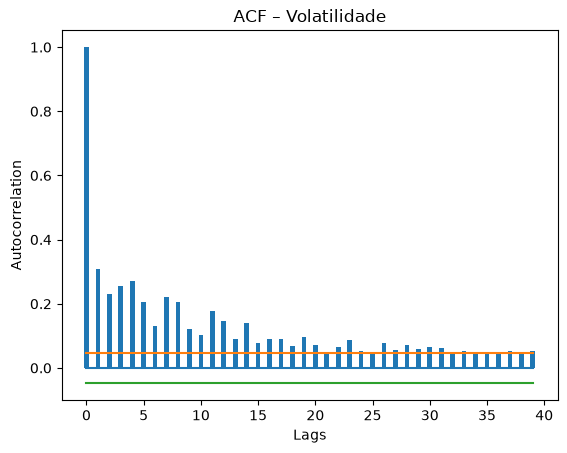

In [4]:
for nome, dataset in bases.items():
    datasetSeries, trainSize, validSize = preparar(dataset)
    acf_plot(datasetSeries, 40, f"ACF – {nome}")
    if nome != "Volatilidade":
        acf_plot(datasetSeries.diff().dropna(), 40, f"ACF – variação diária de {nome}")

## Escolha do lag pelo MSE de validação

Mesmo laço do professor (`for dim in range(1, dimension+1)`), repetido para cada série. Além de `stepahead = 1`, testamos `stepahead = 2` (previsão de 2 dias à frente), que é o horizonte usado no nosso pipeline.

Como referência, calculamos também o MSE do **modelo ingênuo** (prever que o valor de amanhã será igual ao de hoje). Se o modelo linear não for melhor que ele, os lags não estão ajudando.

In [5]:
dimension = 30
HORIZONTES = [1, 2]

resultados = []
erros_validacao = {}
melhores = {}

for nome, dataset in bases.items():
    datasetSeries, trainSize, validSize = preparar(dataset)
    for stepahead in HORIZONTES:
        bestValue = 10**10
        erroBar = []
        for dim in range(1, dimension + 1):
            b = janelas(datasetSeries, dim, stepahead, trainSize, validSize)
            # coluna de 1s = intercepto (nas três bases; ver correção no topo)
            train, valid, test = (np.hstack((b[k][0], np.ones((len(b[k][0]), 1)))) for k in ("train", "valid", "test"))
            trainTarget, validTarget, testTarget = b["train"][1], b["valid"][1], b["test"][1]

            X_inv = np.linalg.pinv(train)
            coefs = X_inv.dot(trainTarget)
            predVal = coefs.dot(valid.T)
            erro = mse(predVal, validTarget)
            erroBar.append(erro)
            if erro < bestValue:
                bestValue, bestDim = erro, dim
                model, test_aux, testTarget_aux = coefs, test, testTarget

        predTest = model.dot(test_aux.T)
        # ingênuo: o último valor conhecido (primeira coluna de entrada) como previsão
        ingenuo = test_aux[:, 0]
        erros_validacao[(nome, stepahead)] = erroBar
        melhores[(nome, stepahead)] = (predTest, testTarget_aux)
        resultados.append({
            "série": nome, "stepahead": stepahead, "melhor lag": bestDim,
            "MSE validação": bestValue,
            "MSE teste": mse(predTest, testTarget_aux),
            "MSE teste (lag 12)": None,
            "MSE teste ingênuo": mse(ingenuo, testTarget_aux),
        })

        # referência: dimensão 12, usada hoje no pipeline (IA_DIMENSAO)
        b = janelas(datasetSeries, 12, stepahead, trainSize, validSize)
        train, test = (np.hstack((b[k][0], np.ones((len(b[k][0]), 1)))) for k in ("train", "test"))
        coefs12 = np.linalg.pinv(train).dot(b["train"][1])
        resultados[-1]["MSE teste (lag 12)"] = mse(coefs12.dot(test.T), b["test"][1])

resultados = pd.DataFrame(resultados)
print("MSE na escala normalizada [0, 1] do treino")
resultados.style.format({c: "{:.6f}" for c in resultados.columns if c.startswith("MSE")})

MSE na escala normalizada [0, 1] do treino


,série,stepahead,melhor lag,MSE validação,MSE teste,MSE teste (lag 12),MSE teste ingênuo
0,Dólar,1,1,0.000486,0.000486,0.000503,0.000490
1,Dólar,2,1,0.001038,0.000873,0.000881,0.000887
2,Petrobras,1,1,0.000389,0.000660,0.000651,0.000652
3,Petrobras,2,17,0.000816,0.001395,0.001409,0.001411
4,Volatilidade,1,14,0.001316,0.001308,0.001322,0.002150
5,Volatilidade,2,13,0.001374,0.001355,0.001369,0.002479


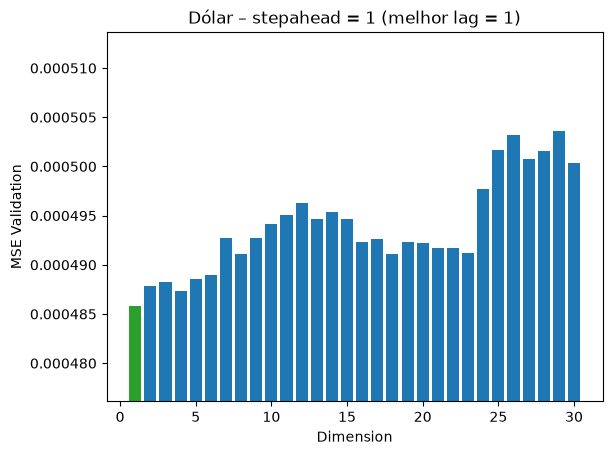

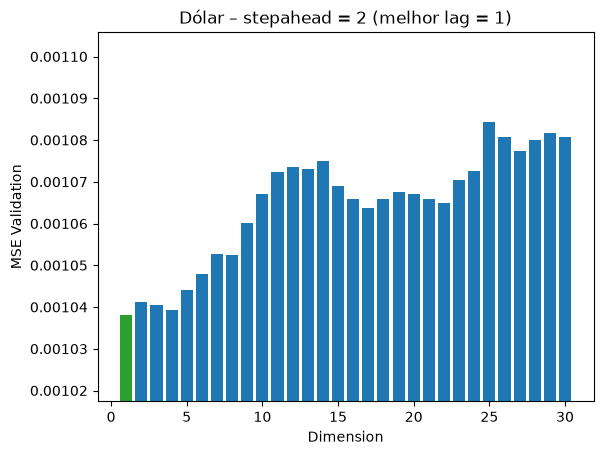

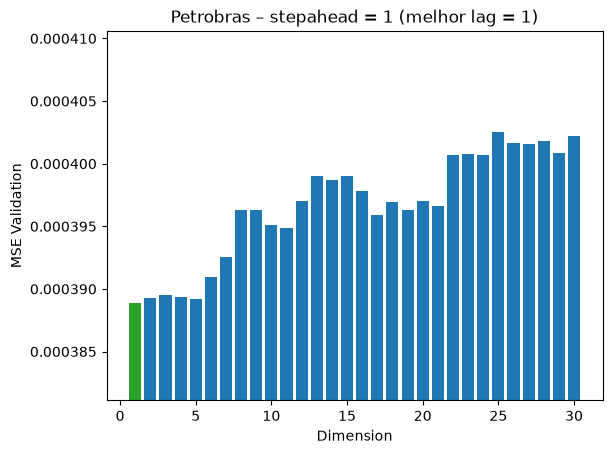

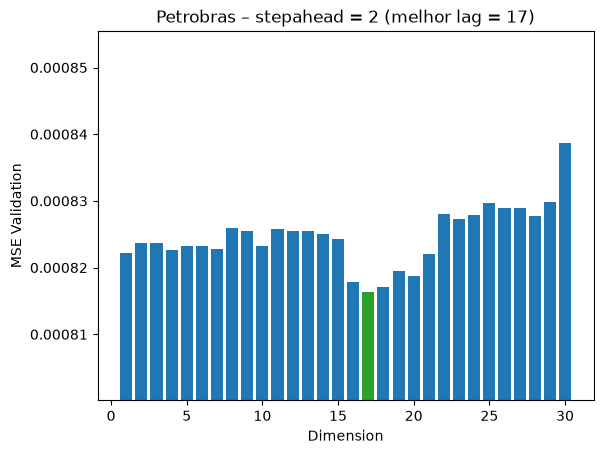

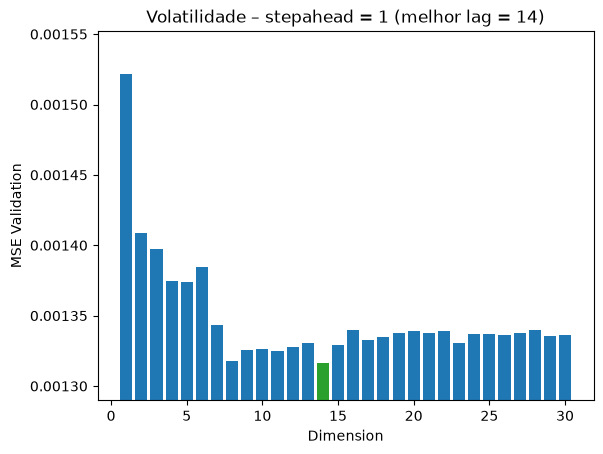

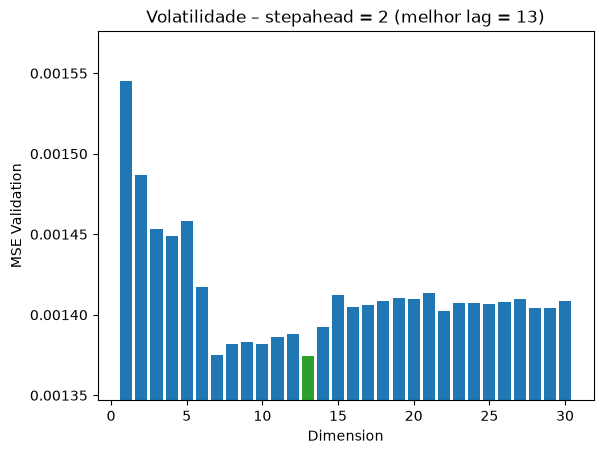

In [6]:
for (nome, stepahead), erroBar in erros_validacao.items():
    melhor = int(np.argmin(erroBar)) + 1
    cores = ["tab:green" if d == melhor else "tab:blue" for d in range(1, dimension + 1)]
    plt.bar(range(1, dimension + 1), erroBar, color=cores)
    plt.ylim(min(erroBar) * 0.98, max(erroBar) * 1.02)   # aproxima para ver as diferenças
    plt.xlabel("Dimension")
    plt.ylabel("MSE Validation")
    plt.title(f"{nome} – stepahead = {stepahead} (melhor lag = {melhor})")
    plt.show()

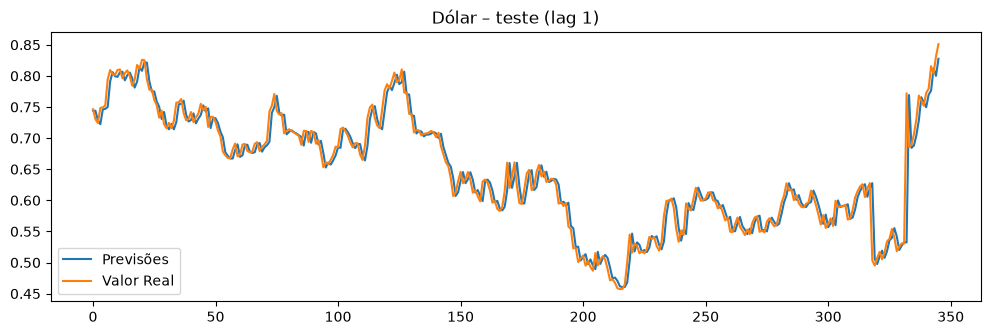

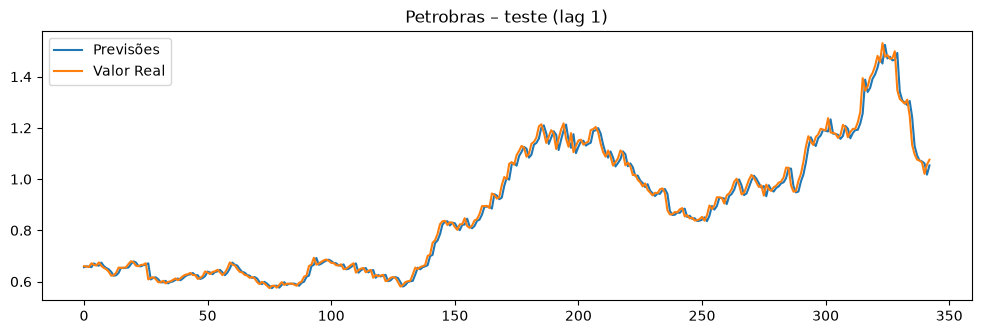

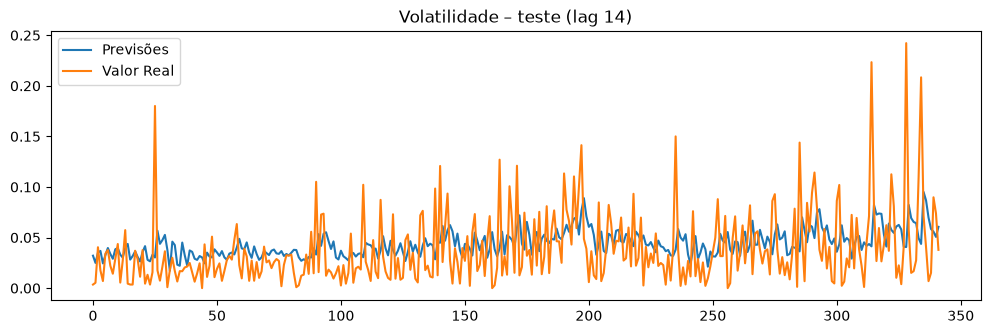

In [7]:
# Previsões x valor real no teste (melhor lag, stepahead = 1), como no exemplo
for nome in bases:
    predTest, testTarget_aux = melhores[(nome, 1)]
    plt.figure(figsize=(12, 3.5))
    plt.plot(predTest)
    plt.plot(testTarget_aux)
    plt.legend(["Previsões", "Valor Real"])
    plt.title(f"{nome} – teste (lag {resultados.query('`série` == @nome and stepahead == 1')['melhor lag'].iloc[0]})")
    plt.show()

In [8]:
melhor_lag = {nome: int(resultados.query("`série` == @nome and stepahead == 1")["melhor lag"].iloc[0])
              for nome in bases}
print("Melhor lag (stepahead = 1), usado no notebook 02 do SVR:", melhor_lag)

Melhor lag (stepahead = 1), usado no notebook 02 do SVR: {'Dólar': 1, 'Petrobras': 1, 'Volatilidade': 14}


## Conclusões

Resultados com os dados até 13/11/2026.

**Autocorrelação**
- **Dólar e Petrobras**: a ACF fica muito alta e cai devagar (lag 1 ≈ 0,99; lag 39 ≈ 0,60 no dólar e 0,79 na Petrobras). Todos os 39 lags passam do limite, porque o preço de hoje fica muito perto do de ontem. Na **variação diária**, só alguns lags isolados passam do limite, e por pouco. Ou seja, quase não há padrão a aproveitar além do último valor.
- **Volatilidade**: a ACF começa em ≈ 0,31 e cai aos poucos (≈ 0,10 no lag 10). Dias agitados vêm em sequência, então vários dias passados ajudam a prever.

**Melhor lag pelo MSE de validação**

| série | stepahead = 1 | stepahead = 2 |
|---|---|---|
| Dólar | **1** | 1 |
| Petrobras | **1** | 17 |
| Volatilidade | **14** | 13 |

**Comparação no teste (MSE)**
- **Volatilidade**: o melhor lag (14) erra **≈ 40% menos** que o modelo ingênuo (0,00131 contra 0,00215). Aqui os lags realmente ajudam.
- **Dólar e Petrobras**: o modelo linear fica **no mesmo nível do ingênuo** (Petrobras h = 1: 0,00066 contra 0,00065). É o comportamento esperado de preço, em que a melhor previsão é o último valor. O lag 17 da Petrobras em h = 2 ganha da validação por uma diferença muito pequena e não melhora o teste.
- O lag **12** usado hoje no pipeline dá resultados praticamente iguais aos dos melhores lags. As diferenças ficam abaixo de 2%.

**Lags escolhidos para o SVR (stepahead = 1):** dólar = 1, Petrobras = 1, volatilidade = 14.